# 🤖 Machine Learning Models (Lost & Found Matcher)
This notebook trains and evaluates the 4 core Machine Learning algorithms:
1. **Multiclass Classification:** Random Forest Classifier (predicts item category)
2. **Text Similarity:** TF-IDF + Cosine Similarity
3. **Binary Classification:** Logistic Regression (predicts potential matches)
4. **Unsupervised Learning:** K-Means Clustering + PCA 2D Visualization


In [1]:
import os
import re
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

os.makedirs("models", exist_ok=True)
print("Libraries imported successfully!")


Libraries imported successfully!


### Step 1: Text Preprocessing & Cleaning
We convert text to lowercase, remove punctuation, and filter out common stopwords.


In [2]:
STOPWORDS = set([
    "a", "about", "above", "after", "again", "against", "all", "am", "an", "and", "any", "are", "aren't",
    "as", "at", "be", "because", "been", "before", "being", "below", "between", "both", "but", "by",
    "can't", "cannot", "could", "did", "do", "does", "doing", "don't", "down", "during", "each", "few",
    "for", "from", "further", "had", "has", "have", "having", "he", "her", "here", "hers", "him", "his",
    "how", "i", "if", "in", "into", "is", "isn't", "it", "its", "me", "more", "most", "my", "myself",
    "no", "nor", "not", "of", "off", "on", "once", "only", "or", "other", "our", "ours", "out", "over",
    "own", "same", "she", "should", "so", "some", "such", "than", "that", "the", "their", "theirs", "them",
    "then", "there", "these", "they", "this", "those", "through", "to", "too", "under", "until", "up",
    "very", "was", "wasn't", "we", "were", "what", "when", "where", "which", "while", "who", "whom",
    "why", "with", "would", "you", "your", "yours"
])

def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)
    tokens = text.split()
    filtered = [t for t in tokens if t not in STOPWORDS and len(t) > 1]
    return " ".join(filtered)

sample = "Found a black leather bi-fold wallet on 2nd floor library reading desk!"
print("Original :", sample)
print("Cleaned  :", clean_text(sample))


Original : Found a black leather bi-fold wallet on 2nd floor library reading desk!
Cleaned  : found black leather bi fold wallet 2nd floor library reading desk


### Step 2: Multiclass Classification - Random Forest Classifier
Trains an ensemble of 100 Decision Trees to predict category from description.


In [3]:
df_items = pd.read_csv("data/items_dataset.csv")
df_items["clean_desc"] = df_items["description"].apply(clean_text)

X = df_items["clean_desc"]
y = df_items["category"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

vec_rf = TfidfVectorizer(max_features=1000, ngram_range=(1, 2))
X_train_vec = vec_rf.fit_transform(X_train)
X_test_vec = vec_rf.transform(X_test)

rf_clf = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42)
rf_clf.fit(X_train_vec, y_train)

y_pred_rf = rf_clf.predict(X_test_vec)
rf_acc = accuracy_score(y_test, y_pred_rf)
print(f"🎯 Random Forest Test Accuracy: {rf_acc * 100:.2f}%")
print(classification_report(y_test, y_pred_rf))

# Save models
joblib.dump(rf_clf, "models/category_classifier.pkl")
joblib.dump(vec_rf, "models/category_tfidf.pkl")


🎯 Random Forest Test Accuracy: 98.41%
              precision    recall  f1-score   support

         Bag       0.90      1.00      0.95         9
        Keys       1.00      1.00      1.00         9
      Laptop       1.00      1.00      1.00         9
Mobile Phone       1.00      1.00      1.00         9
       Other       1.00      0.89      0.94         9
      Wallet       1.00      1.00      1.00         9
       Watch       1.00      1.00      1.00         9

    accuracy                           0.98        63
   macro avg       0.99      0.98      0.98        63
weighted avg       0.99      0.98      0.98        63


### Random Forest Confusion Matrix


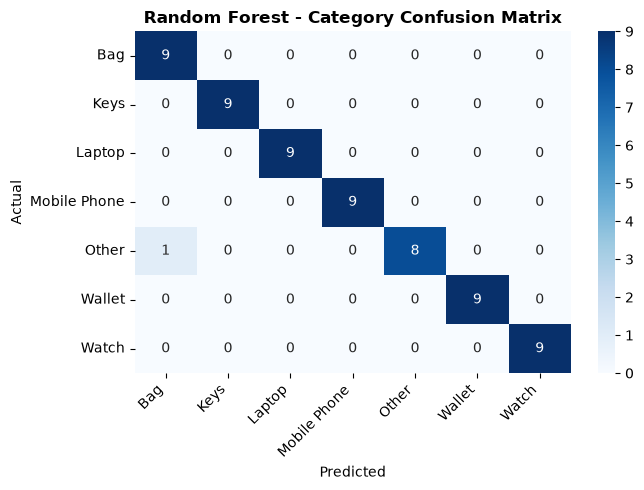

In [4]:
labels = sorted(list(df_items["category"].unique()))
cm = confusion_matrix(y_test, y_pred_rf, labels=labels)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Random Forest - Category Confusion Matrix", fontweight='bold')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


### Step 3: Text Similarity - TF-IDF + Cosine Similarity


In [5]:
def compute_similarity(text1, text2):
    c1, c2 = clean_text(text1), clean_text(text2)
    vec = TfidfVectorizer()
    mat = vec.fit_transform([c1, c2])
    return float(cosine_similarity(mat[0:1], mat[1:2])[0][0])

t1 = "Lost black leather wallet in library"
t2 = "Found dark leather wallet with cards near library study tables"
t3 = "Found silver Acer laptop in lecture hall"

print(f"Sim(t1, t2) [Matching]: {compute_similarity(t1, t2)*100:.1f}%")
print(f"Sim(t1, t3) [Different]: {compute_similarity(t1, t3)*100:.1f}%")


Sim(t1, t2) [Matching]: 29.5%
Sim(t1, t3) [Different]: 0.0%


### Step 4: Binary Classification - Logistic Regression Match Classifier


In [6]:
df_match = pd.read_csv("data/matching_dataset.csv")
feature_cols = ["text_similarity", "same_category", "same_color", "same_location", "date_diff_days"]

X_m = df_match[feature_cols]
y_m = df_match["is_match"]

X_tr_m, X_te_m, y_tr_m, y_te_m = train_test_split(X_m, y_m, test_size=0.2, random_state=42, stratify=y_m)

log_reg = LogisticRegression(random_state=42, max_iter=500)
log_reg.fit(X_tr_m, y_tr_m)

y_pred_m = log_reg.predict(X_te_m)
lr_acc = accuracy_score(y_te_m, y_pred_m)
print(f"🎯 Logistic Regression Test Accuracy: {lr_acc * 100:.2f}%")
print(classification_report(y_te_m, y_pred_m))

joblib.dump(log_reg, "models/match_classifier.pkl")


🎯 Logistic Regression Test Accuracy: 100.00%
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        24
           1       1.00      1.00      1.00        21

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45


### Visualizing Logistic Regression Learned Weights


Weights:
  text_similarity: +2.1980
  same_color     : +1.7739
  same_category  : +1.7570
  same_location  : +1.3702
  date_diff_days : -0.2484
  Intercept      : -1.5956


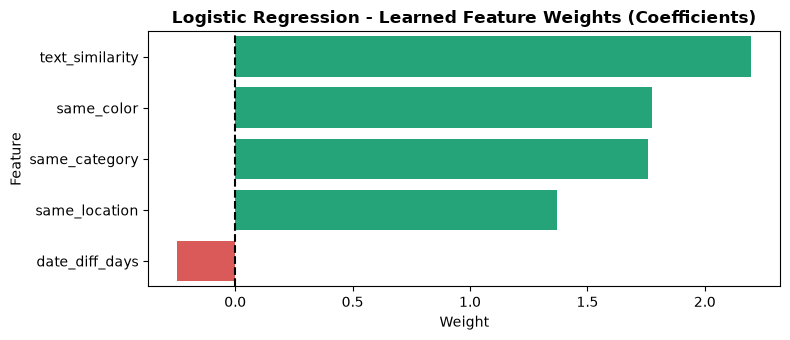

In [7]:
coef_df = pd.DataFrame({
    "Feature": feature_cols,
    "Weight": log_reg.coef_[0]
}).sort_values(by="Weight", ascending=False)

plt.figure(figsize=(8, 3.5))
colors = ['#10B981' if w > 0 else '#EF4444' for w in coef_df["Weight"]]
sns.barplot(x="Weight", y="Feature", data=coef_df, palette=colors)
plt.axvline(0, color='black', linestyle='--')
plt.title("Logistic Regression - Learned Feature Weights (Coefficients)", fontweight='bold')
plt.tight_layout()
plt.show()

print("Weights:")
for _, r in coef_df.iterrows():
    print(f"  {r['Feature']:15s}: {r['Weight']:+.4f}")
print(f"  Intercept      : {log_reg.intercept_[0]:+.4f}")


### Step 5: Unsupervised Learning - K-Means Clustering + PCA 2D Projection


All Machine Learning models trained, evaluated, and saved successfully!


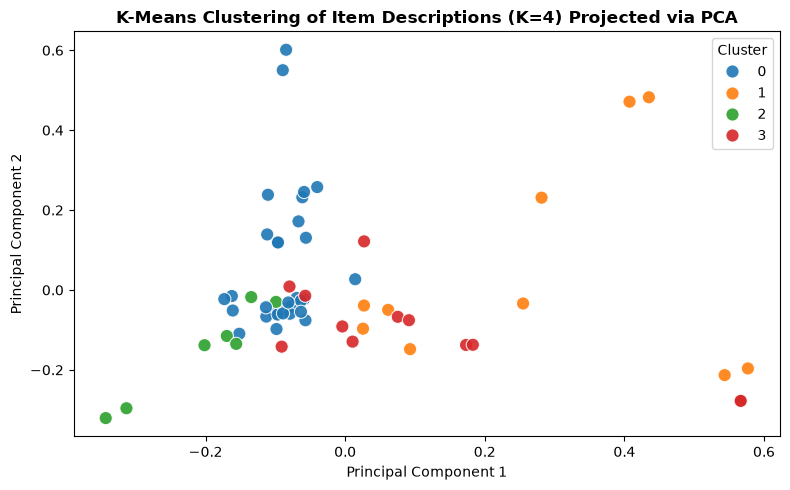

In [8]:
from sklearn.decomposition import PCA

descriptions = df_items["description"].tolist()[:60]
cleaned = [clean_text(d) for d in descriptions]

vec_km = TfidfVectorizer(max_features=500, stop_words="english")
X_tfidf_km = vec_km.fit_transform(cleaned)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_km = kmeans.fit_predict(X_tfidf_km)

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_tfidf_km.toarray())

plt.figure(figsize=(8, 5))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=labels_km, palette="tab10", s=90, alpha=0.9)
plt.title("K-Means Clustering of Item Descriptions (K=4) Projected via PCA", fontweight='bold')
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print("All Machine Learning models trained, evaluated, and saved successfully!")
